### Downloadin and preparing the video

Note: you may need to restart the kernel to use updated packages.
Get:1 http://deb.debian.org/debian bookworm InRelease [151 kB]
Get:2 http://deb.debian.org/debian bookworm-updates InRelease [55.4 kB]        
Get:3 http://deb.debian.org/debian-security bookworm-security InRelease [48.0 kB]
Get:4 https://dl.yarnpkg.com/debian stable InRelease [17.1 kB]
Get:5 http://deb.debian.org/debian bookworm/main amd64 Packages [8789 kB]
Get:6 https://dl.yarnpkg.com/debian stable/main all Packages [10.9 kB]
Get:7 https://dl.yarnpkg.com/debian stable/main amd64 Packages [10.9 kB]       
Get:8 http://deb.debian.org/debian bookworm-updates/main amd64 Packages [2468 B]
Get:9 http://deb.debian.org/debian-security bookworm-security/main amd64 Packages [204 kB]
Fetched 9289 kB in 2s (5015 kB/s)                       
Reading package lists... Done
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
libxext6 is already the newest version (2:1.3.4-1+b1).
libxext6 s

/workspaces/eng-ai-agents/.venv/lib/python3.11/site-packages/torchvision/io/video.py:169: UserWarning: The pts_unit 'pts' gives wrong results. Please use pts_unit 'sec'.
  warnings.warn("The pts_unit 'pts' gives wrong results. Please use pts_unit 'sec'.")


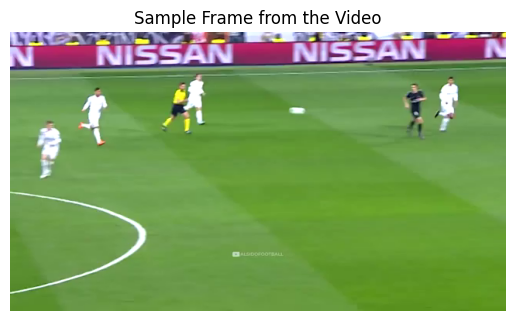

In [1]:
%pip install pytubefix
!sudo apt-get update && sudo apt-get install ffmpeg libsm6 libxext6 libgl1  -y

from pytubefix import YouTube
import os
from torchvision.io import read_video, write_png
import matplotlib.pyplot as plt

yt = YouTube('https://www.youtube.com/watch?v=l3NJNFmg09k')
out = yt.streams.filter(progressive=True, file_extension='mp4').order_by('resolution').desc().first().download()
video_path = 'input.mp4'
os.rename(out, video_path)

video, audio, meta = read_video(video_path)
frames = video.permute(0, 3, 1, 2)

plt.imshow(frames[0].permute(1, 2, 0))
plt.title("Sample Frame from the Video")
plt.axis("off")
plt.show()

write_png(frames[0], "sample.png")

### Model Overview
Firstly we gonna take a look at the FasterRCNN model layers implemented in pytorch before we take a closer look at the at the RPN and ROI Layers.

#### 1. Transform:
This applies preprocessing transformations to input images.

#### 2. Backbone with FPN (Feature Pyramid Network):

- Body: A ResNet50 for extracting features from the input images. It includes convolutional and batch normalization layers, interspersed with ReLU activations. This structure progressively extracts higher-level features at different spatial scales.
- FPN: The Feature Pyramid Network builds a feature hierarchy to detect objects at multiple scales, with inner and layer blocks that refine and enrich features at various resolutions.

#### 3. Region Proposal Network (RPN):

- Anchor Generator: Generates anchor boxes (predefined bounding boxes) across the image at multiple scales and aspect ratios.
- RPN Head: A small network that classifies anchors as background or foreground and adjusts their positions for more accurate proposals.

#### 4. RoI Heads:

- RoI Pooling (MultiScaleRoIAlign): Extracts features of each region of interest (RoI) proposed by the RPN and resizes them to a fixed size (7x7).
- Box Head: A fully connected head for further processing the RoI features. It consists of several convolutional and fully connected layers, ending in a classification and a bounding box regression head.
- Box Predictor: Outputs the final class scores and bounding box adjustments.

This Faster R-CNN model uses a deep convolutional backbone with a feature pyramid, enabling it to handle object detection across scales efficiently. The RPN suggests candidate regions, and the RoI head processes these regions to classify and refine their bounding boxes

# TODO SHOW ROUGH BLOCK DIAGRAM OF NETWORK !!!!

In [2]:
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using {device}")

weights = FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT
preprocess = weights.transforms()
model = fasterrcnn_resnet50_fpn_v2(weights=weights, box_score_thresh=0.9 )
model = model.to(device)
model.eval()

### Registering Hooks to visualize each layer
activation = {}
def getActivation(name):
    def hook(model, input, output):
        activation[name] = output
    return hook

for name, child  in model.named_children():
    print(f"{name} :  {child}")
    handle = child.register_forward_hook(getActivation(name))

#### Sample prediction for one Frame to show activation
input_frame = preprocess(frames[0]).to(device)

with torch.no_grad():
    prediction = model([input_frame])[0]

Using cuda
transform :  GeneralizedRCNNTransform(
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    Resize(min_size=(800,), max_size=1333, mode='bilinear')
)
backbone :  BackboneWithFPN(
  (body): IntermediateLayerGetter(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv3): Conv2d(64, 256, kernel_

#### Transform Layer
This Layer takes in the Input Image and it normalizes it with a given mean and standard deviation and resizes them to fit the model's expected input dimensions.

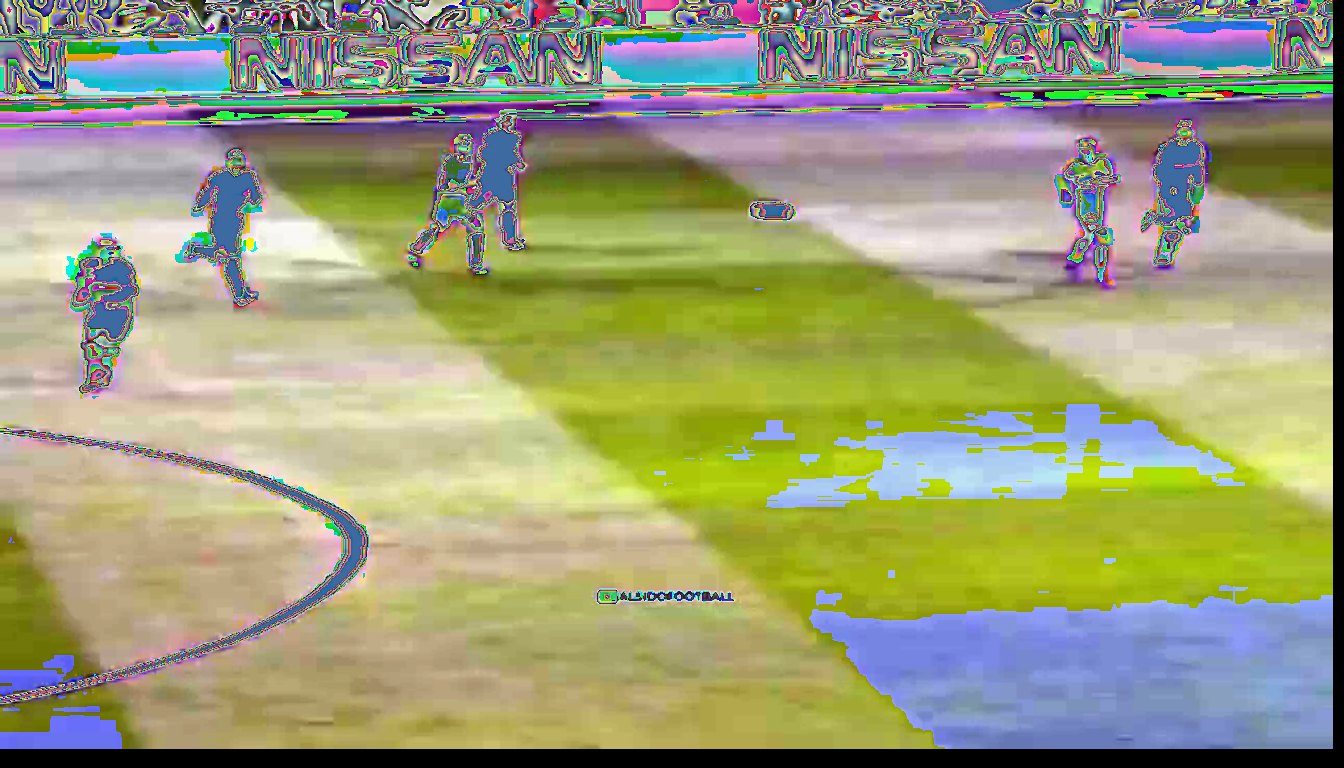

In [3]:
from torchvision.transforms.functional import to_pil_image

transformed_images, _ = activation["transform"]

transformed_image = transformed_images.tensors[0]

transformed_pil_image = to_pil_image(transformed_image)
transformed_pil_image.show(title="Transformed Image")

#### Backbone Layer
The Backpone Layer, in this case a pretrained ResNet50 with FPN, takes in the transformed image and and extracts the feautre map for the following Layers.

Feature map '0' shape: torch.Size([1, 256, 192, 336])
Feature map '1' shape: torch.Size([1, 256, 96, 168])
Feature map '2' shape: torch.Size([1, 256, 48, 84])
Feature map '3' shape: torch.Size([1, 256, 24, 42])
Feature map 'pool' shape: torch.Size([1, 256, 12, 21])


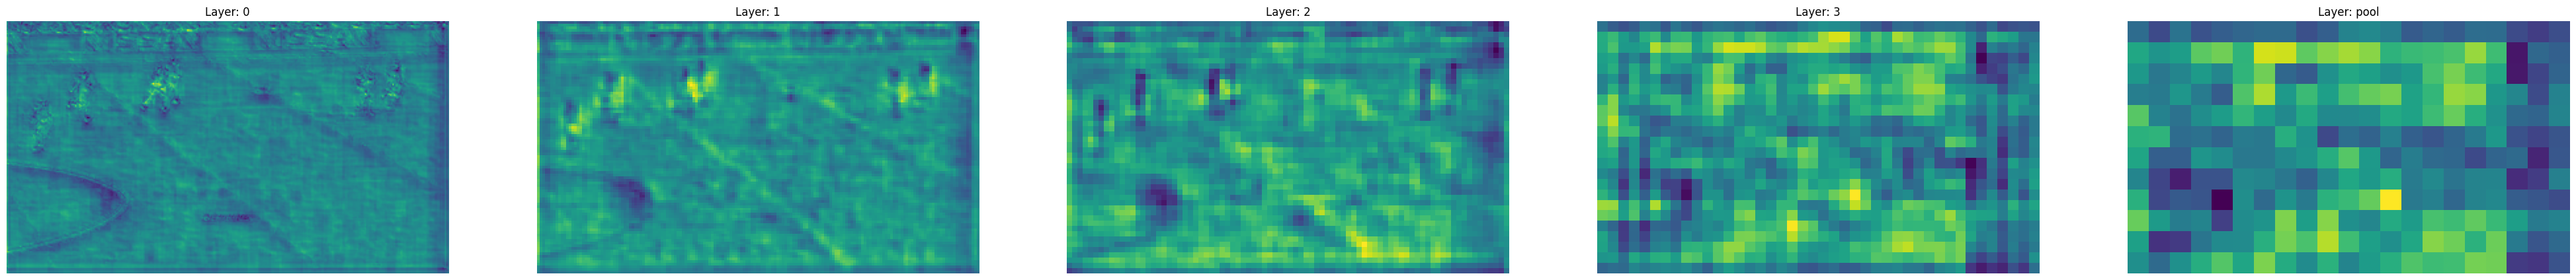

In [4]:
import matplotlib.pyplot as plt
backbone_features = activation['backbone']

fig = plt.figure(figsize=(50, 50))

for i, (k, v) in enumerate(backbone_features.items()):
    print(f"Feature map '{k}' shape: {v.shape}")
    feature_map = backbone_features[k][0]
    feature_map_mean = feature_map.mean(dim=0)

    feature_map_norm = (feature_map_mean - feature_map_mean.min()) / (feature_map_mean.max() - feature_map_mean.min())

    a = fig.add_subplot(1, 5, i+1)
    imgplot = plt.imshow(feature_map_norm.cpu().detach())
    a.set_title(f"Layer: {k}")
    a.axis("off")

plt.show()

#### Region Proposal Network (RPN)
The RPN takes in the Feature map from the previus layer.

At each feature map region, the RPN places anchor boxes of various scales and aspect ratios in this case 9 per cell with varying shapes and sizes. This creates a dense set of boxes across the entire feature map that could potentially contain objects.

##### Binary Classification and Bounding Box Regression:

For each anchor box, the RPN performs two tasks:
- Binary classification: It predicts whether each anchor is likely to contain an object (foreground) or is background.
- Bounding box regression: For anchors classified as foreground, the RPN also predicts adjustments to refine the anchor box coordinates, making them better fit the object it encloses.

- Output: The RPN then filters out the anchor boxes based on their scores (confidence in being foreground) and applies non-maximum suppression to remove redundant boxes. The result is a set of region proposals that are likely to contain objects.

The key idea here is that the RPN essentially learns to suggest potential object locations with a high probability and good positioning, reducing the number of regions Faster R-CNN needs to inspect in detail.

# TODO INCORPARATE PYTORCH SOURCECODE AND DIAGRAM

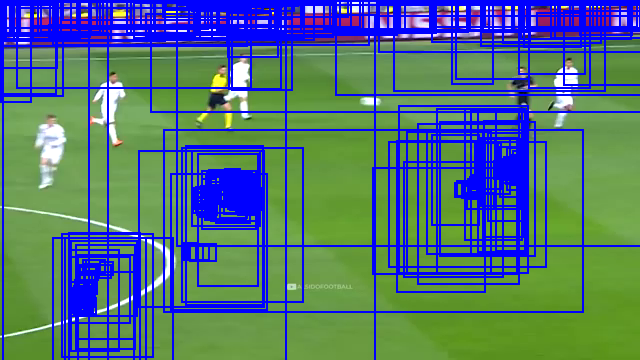

In [ ]:
from torchvision.ops import nms
from torchvision.utils import draw_bounding_boxes

rpn_outputs = activation['rpn']

proposals = rpn_outputs[0]

proposals_per_image = proposals[0]

# WHY ? -> Score must be cuda error
#keep = nms(proposals_per_image, torch.ones(proposals_per_image.size(0)), iou_threshold=0.7)
#proposals_per_image = proposals_per_image[keep]

num_proposals_to_draw = 500
proposals_to_draw = proposals_per_image[:num_proposals_to_draw]

img_uint8 = (input_frame * 255).type(torch.uint8)
img_with_proposals = draw_bounding_boxes(img_uint8, boxes=proposals_to_draw, colors="blue", width=2)

img_with_proposals_pil = to_pil_image(img_with_proposals)
img_with_proposals_pil.show(title="RPN Proposals")


#### ROI Pooling Layer
The RoI (Regions of Interest) Pooling layer takes in the RoI e.g bounding box proposal of diffrent size from the RPN. It then divides each RoI into a 7x7 bins and applys Max Pooling on each bin to obtain a fixed-size feature map of shape 7x7xC for each RoI. The depth (number of channels) remains the same as the input feature map. This Step converts variable-sized RoIs into fixed-size feature maps, allowing them to be processed uniformly in the subsequent layers.

##### Prediction Heads
After RoI pooling, each fixed-size feature map (e.g., 7x7xC) is flattened into a 1D vector. This is necessary to feed the features into fully connected (FC) layers.

Two Separate Heads:

- Classification Head: This branch consists of a few fully connected layers that process the flattened feature vector to predict the class probabilities for each RoI. It essentially outputs a probability distribution over all possible object classes plus a "background" class.
- Bounding Box Regression Head: This branch also has a few fully connected layers that predict bounding box adjustments. It outputs refined coordinates (e.g., adjustments to the x, y, width, and height) for the RoI, fine-tuning the bounding box location and dimensions to better fit the detected object.

Final Output: After these heads, you get the final detections:

- A class label (or background) for each RoI.
- Refined bounding box coordinates for each detected object.

# TODO INTEGRATE PYTORCH SOURCE CODE AND DIAGRAM

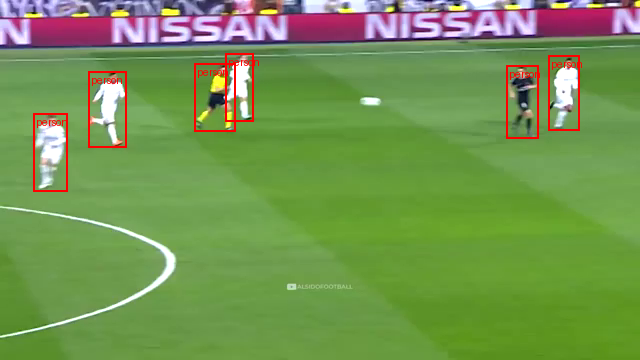

In [6]:
roi_heads_outputs = activation['roi_heads']

detections = roi_heads_outputs[0]

detection = detections[0]

scores = detection['scores']
keep_idxs = scores > 0.9
boxes = detection['boxes'][keep_idxs]
labels = detection['labels'][keep_idxs]

category_names = [weights.meta["categories"][i] for i in labels]

img_with_detections = draw_bounding_boxes(img_uint8, boxes=boxes, labels=category_names, colors="red", width=2)
img_with_detections_pil = to_pil_image(img_with_detections)
img_with_detections_pil.show(title="Final Detections")

### Run detection on each Frame

In [7]:
from tqdm import tqdm

output_frames = []

for frame in tqdm(frames, desc="Processing Frames"):
    input_frame = preprocess(frame).to(device)

    with torch.no_grad():
        prediction = model([input_frame])[0]

    labels = [weights.meta["categories"][i] for i in prediction["labels"]]
    box = draw_bounding_boxes(frame,
                            boxes=prediction["boxes"],
                            labels=labels,
                            colors="blue",
                            width=2,
                            font_size=30)

    output_frames.append(box.to(torch.uint8))

Processing Frames:   0%|          | 0/1074 [00:00<?, ?it/s]/workspaces/eng-ai-agents/.venv/lib/python3.11/site-packages/torchvision/utils.py:225: UserWarning: Argument 'font_size' will be ignored since 'font' is not set.
  warnings.warn("Argument 'font_size' will be ignored since 'font' is not set.")
Processing Frames: 100%|██████████| 1074/1074 [13:09<00:00,  1.36it/s]


#### Create the output video

In [8]:

from torchvision.io import write_video

output_video = torch.stack(output_frames).permute(0, 2, 3, 1)  # Shape (T, H, W, C)
write_video(
    "output.mp4",
    video_array=output_video,
    audio_array=audio,
    audio_codec='aac',
    audio_fps=int(meta['audio_fps']),
    fps=int(meta['video_fps']),
    video_codec='h264',
    options={'crf': '18'}
)

### FOR TESTING ONLY !!!
Testing visualization of FasterRCNN on a dog image

transform (<torchvision.models.detection.image_list.ImageList object at 0x7f91b65cd190>, None)
rpn ([tensor([[ 337.1253,    6.4317, 1141.3126,  800.0000],
        [ 127.6543,   79.0002,  947.1300,  773.7926],
        [ 376.5301,    4.1034,  751.1228,  184.2440],
        ...,
        [   0.0000,  554.5192,  222.8226,  784.0046],
        [   0.0000,    0.0000,  112.3348,  315.4946],
        [   7.6610,    0.0000,  217.6595,  162.9406]])], {})
roi_heads ([{'boxes': tensor([[  3.6536,   6.5189, 398.0475, 270.8237]], grad_fn=<StackBackward0>), 'labels': tensor([18]), 'scores': tensor([0.9917], grad_fn=<IndexBackward0>)}], {})


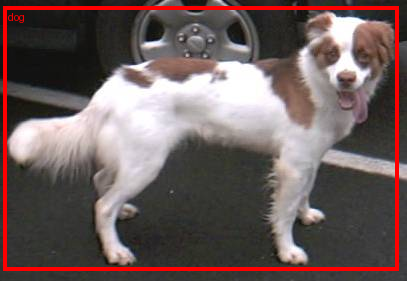

In [9]:
from torchvision.io import decode_image
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights
from torchvision.utils import draw_bounding_boxes
from torchvision.transforms.functional import to_pil_image

weights = FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT
model = fasterrcnn_resnet50_fpn_v2(weights=weights, box_score_thresh=0.9)
model.eval()

img = decode_image("../assignment-2a/dogscats/subset/test/dogs/dog.1500.jpg", mode="RGB")
preprocess = weights.transforms()

# Step 3: Apply inference preprocessing transforms
batch = [preprocess(img)]

### Show each layer
activation = {}
def getActivation(name):
    def hook(model, input, output):
        activation[name] = output
    return hook

for name, child  in model.named_children():
    handle = child.register_forward_hook(getActivation(name))

prediction = model(batch)[0]

for i, name in enumerate(activation):
    if name != "backbone":
        print(name, activation[name])


### Final Output
labels = [weights.meta["categories"][i] for i in prediction["labels"]]
box = draw_bounding_boxes(img, boxes=prediction["boxes"],
                          labels=labels,
                          colors="red",
                          width=4, font_size=30)
im = to_pil_image(box.detach())
im.show()

In [10]:
import torch
from torchvision.io import read_image
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights
from torchvision.utils import draw_bounding_boxes
from torchvision.transforms.functional import to_pil_image
import matplotlib.pyplot as plt

# Step 1: Initialize model with the best available weights
weights = FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT
model = fasterrcnn_resnet50_fpn_v2(weights=weights, box_score_thresh=0.9)
model.eval()

# Read the image
img_path = "../assignment-2a/dogscats/subset/test/dogs/dog.1500.jpg"
img = read_image(img_path).float() / 255.0  # Normalize to [0,1]

# Original image size
original_image_size = img.shape[-2:]  # (C, H, W)

# Prepare a batch
batch = [img]

# Prepare activation dict
activation = {}
def getActivation(name):
    def hook(model, input, output):
        activation[name] = output
    return hook

# Register hooks
for name, child in model.named_children():
    child.register_forward_hook(getActivation(name))

# Run inference
with torch.no_grad():
    prediction = model(batch)



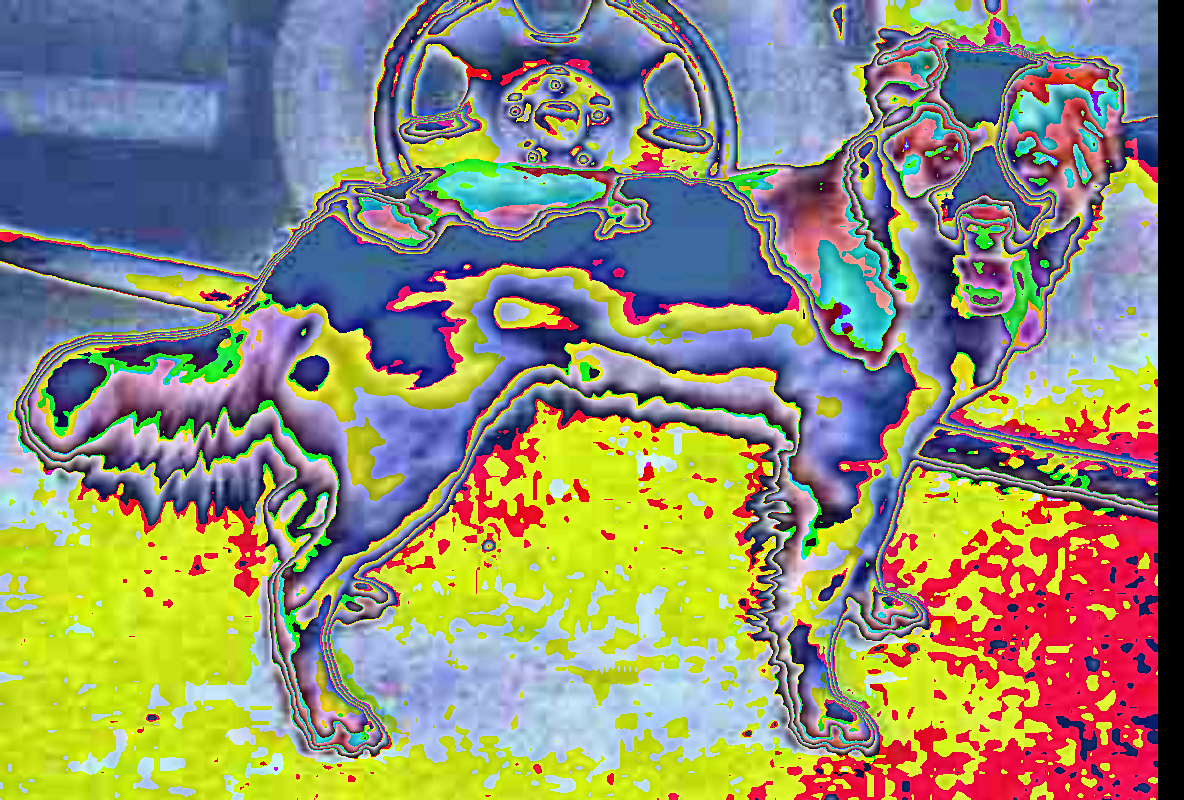

In [11]:
transformed_images, _ = activation["transform"]

transformed_image = transformed_images.tensors[0]

transformed_pil_image = to_pil_image(transformed_image)
transformed_pil_image.show(title="Transformed Image")


Feature map '0' shape: torch.Size([1, 256, 200, 296])
Feature map '1' shape: torch.Size([1, 256, 100, 148])
Feature map '2' shape: torch.Size([1, 256, 50, 74])
Feature map '3' shape: torch.Size([1, 256, 25, 37])
Feature map 'pool' shape: torch.Size([1, 256, 13, 19])


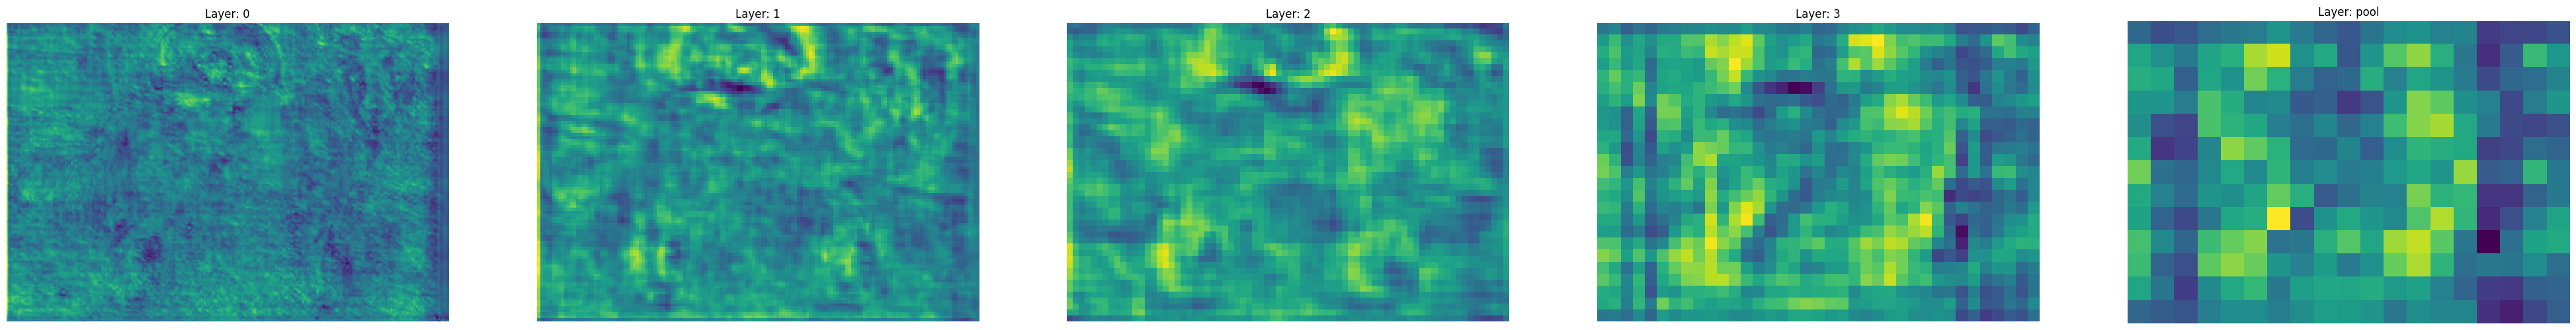

In [12]:
import matplotlib.pyplot as plt
backbone_features = activation['backbone']

fig = plt.figure(figsize=(50, 50))

for i, (k, v) in enumerate(backbone_features.items()):
    print(f"Feature map '{k}' shape: {v.shape}")
    feature_map = backbone_features[k][0]
    feature_map_mean = feature_map.mean(dim=0)

    feature_map_norm = (feature_map_mean - feature_map_mean.min()) / (feature_map_mean.max() - feature_map_mean.min())

    a = fig.add_subplot(1, 5, i+1)
    imgplot = plt.imshow(feature_map_norm)
    a.set_title(f"Layer: {k}")
    a.axis("off")

plt.show()

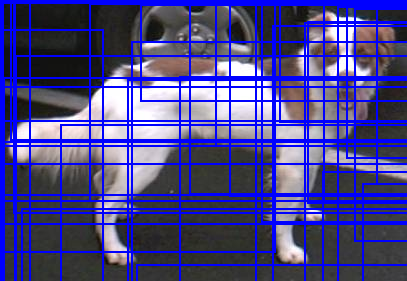

In [13]:
rpn_outputs = activation['rpn']

proposals = rpn_outputs[0]

proposals_per_image = proposals[0]

keep = nms(proposals_per_image, torch.ones(proposals_per_image.size(0)), iou_threshold=0.7)
proposals_per_image = proposals_per_image[keep]

num_proposals_to_draw = 64
proposals_to_draw = proposals_per_image[:num_proposals_to_draw]

img_uint8 = (img * 255).type(torch.uint8)
img_with_proposals = draw_bounding_boxes(img_uint8, boxes=proposals_to_draw, colors="blue", width=2)

img_with_proposals_pil = to_pil_image(img_with_proposals)
img_with_proposals_pil.show(title="RPN Proposals")


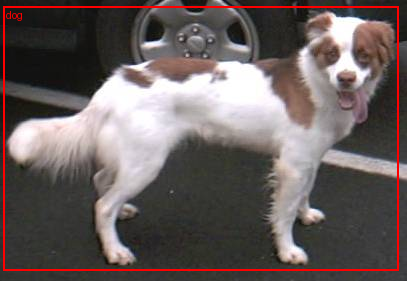

In [14]:
roi_heads_outputs = activation['roi_heads']

detections = roi_heads_outputs[0]

detection = detections[0]

scores = detection['scores']
keep_idxs = scores > 0.9
boxes = detection['boxes'][keep_idxs]
labels = detection['labels'][keep_idxs]

category_names = [weights.meta["categories"][i] for i in labels]

img_with_detections = draw_bounding_boxes(img_uint8, boxes=boxes, labels=category_names, colors="red", width=2)
img_with_detections_pil = to_pil_image(img_with_detections)
img_with_detections_pil.show(title="Final Detections")
